# Monitor de Vaca Muerta · Notebook 01: Exploración
### Parte 3 del proyecto Balance Energético de Argentina

En la Parte 2 vimos que Argentina pasó a exportar energía gracias al petróleo, pero el Balance Energético **no separa por cuenca**,
así que no podía "ver" Vaca Muerta directamente. Ahora trabajamos con datos **pozo por pozo y mes a mes** de la Secretaría de Energía.

**Objetivo de este notebook:** conocer las dos bases antes de limpiarlas o armar la app.
- ¿Qué período cubren?
- ¿Qué tan limpias vienen (nulos, duplicados, valores raros)?
- ¿Cómo evolucionó la producción de Vaca Muerta y quién produce?
- ¿Se pueden unir producción y fracturas? (eso es lo que necesita el modelo de ML de la Etapa 5)

**Bases** (se bajan con `scripts/descargar.py`):

| Archivo | Qué tiene |
|---|---|
| `produccion_no_convencional.csv` | Una fila por **pozo y mes**: petróleo, gas y agua producidos, empresa, yacimiento, formación y coordenadas |
| `fracturas.csv` | Una fila por **fractura**: largo de la rama horizontal, cantidad de etapas, arena, agua, presión |

**Unidades** (según el diccionario de datos del portal): `prod_pet` en **m³** de petróleo y `prod_gas` en **miles de m³** de gas.
Para que los números se entiendan, los pasamos a las unidades que usa la prensa: **barriles por día** y **millones de m³ por día**.

## 0. Preparación

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "grid.color": "#e6e6e3"})
COLOR = {"petroleo": "#2a78d6", "gas": "#1baf7a", "resto": "#9a9994", "texto": "#52514e", "acento": "#eb6834"}

# El notebook vive en notebooks/, por eso las rutas suben un nivel (..)
CRUDOS = Path("..") / "datos" / "crudos"
CARPETA_GRAF = Path("..") / "graficos"
CARPETA_GRAF.mkdir(exist_ok=True)

M3_A_BARRILES = 6.2898   # 1 m³ = 6,2898 barriles

## 1. Producción por pozo

El archivo pesa ~150 MB y tiene 40 columnas. Para no gastar memoria leemos **solo las columnas que vamos a usar**
(`usecols`). Es una buena práctica cuando las bases son grandes.

In [2]:
COLUMNAS = ["idpozo", "anio", "mes", "prod_pet", "prod_gas", "prod_agua", "tef", "empresa", "sigla",
            "formacion", "areayacimiento", "provincia", "coordenadax", "coordenaday",
            "sub_tipo_recurso", "tipopozo", "tipoestado"]
prod = pd.read_csv(CRUDOS / "produccion_no_convencional.csv", usecols=COLUMNAS, low_memory=False)
prod["fecha"] = pd.to_datetime(dict(year=prod["anio"], month=prod["mes"], day=1))

print(f"{len(prod):,} filas · {prod['idpozo'].nunique():,} pozos")
print(f"Período: {prod['fecha'].min():%m/%Y} a {prod['fecha'].max():%m/%Y}")
prod.head()

426,145 filas · 5,126 pozos
Período: 01/2006 a 08/2026


,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,tef,tipoestado,tipopozo,empresa,sigla,formacion,areayacimiento,provincia,coordenadax,coordenaday,sub_tipo_recurso,fecha
0,2016,1,155255,821.180,2110.430,259.19,30.83,Extracción Efectiva,Gasífero,YSUR ENERGÍA ARGENTINA S.R.L.,APA.RN.EFO-252(d),lajas,ESTACION FERNANDEZ ORO,Rio Negro,-67.810494,-39.024280,TIGHT,2016-01-01
1,2018,1,134778,0.000,6.130,4.97,31.00,Extracción Efectiva,Gasífero,YSUR ENERGÍA ARGENTINA S.R.L.,APA.Nq.ACO-10(d),precuyo,ANTICLINAL CAMPAMENTO OESTE,Neuquén,-69.795986,-38.946347,TIGHT,2018-01-01
2,2017,1,157125,236.740,911.520,63.15,31.00,Extracción Efectiva,Gasífero,YSUR ENERGÍA ARGENTINA S.R.L.,YEA.RN.EFO-257(d),lajas,ESTACION FERNANDEZ ORO,Rio Negro,-67.810568,-39.024641,TIGHT,2017-01-01
3,2018,1,130297,4.309,204.757,10.18,31.00,Extracción Efectiva,Gasífero,YSUR ENERGÍA ARGENTINA S.R.L.,AEA.RN.EFO-101(d),lajas,ESTACION FERNANDEZ ORO,Rio Negro,-67.881623,-39.014652,TIGHT,2018-01-01
4,2016,1,132771,68.420,738.870,31.84,30.83,Extracción Efectiva,Gasífero,YSUR ENERGÍA ARGENTINA S.R.L.,APA.RN.EFO-126(d),lajas,ESTACION FERNANDEZ ORO,Rio Negro,-67.838082,-39.019110,TIGHT,2016-01-01


### 1.1 Calidad de los datos

In [3]:
calidad = pd.DataFrame({
    "nulos %": (prod.isna().mean() * 100).round(2),
    # las coordenadas son negativas por estar al sur y al oeste: eso es normal, no las contamos
    "negativos": prod.select_dtypes("number").drop(columns=["coordenadax", "coordenaday"]).lt(0).sum(),
}).fillna(0)
print("Filas duplicadas (mismo pozo y mes):", prod.duplicated(["idpozo", "anio", "mes"]).sum())
calidad[(calidad["nulos %"] > 0) | (calidad["negativos"] > 0)]

Filas duplicadas (mismo pozo y mes): 0


,nulos %,negativos
prod_gas,0.00,2.0
prod_pet,0.00,1.0
sub_tipo_recurso,0.11,0.0
tipoestado,0.15,0.0
tipopozo,0.15,0.0


### 1.2 ¿Qué formaciones hay en la base?

In [4]:
por_formacion = (prod.groupby("formacion")[["prod_pet", "prod_gas"]].sum()
                 .assign(pozos=prod.groupby("formacion")["idpozo"].nunique()))
por_formacion["% del petróleo"] = por_formacion["prod_pet"] / por_formacion["prod_pet"].sum() * 100
por_formacion["% del gas"] = por_formacion["prod_gas"] / por_formacion["prod_gas"].sum() * 100
por_formacion.sort_values("prod_pet", ascending=False).head(8).round(1)

,prod_pet,prod_gas,pozos,% del petróleo,% del gas
formacion,,,,,
vaca muerta,138789456.7,161965924.8,3417,96.5,60.3
lajas,2583969.2,37456105.8,589,1.8,14.0
punta rosada,917742.7,13591368.4,114,0.6,5.1
mulichinco,414027.4,24277355.1,259,0.3,9.0
magallanes,304363.8,9547692.1,201,0.2,3.6
quintuco,193971.8,997570.9,86,0.1,0.4
los molles,174096.5,5468032.5,216,0.1,2.0
precuyo,150428.2,4640252.1,81,0.1,1.7


**Decisión:** a partir de acá nos quedamos con la **formación Vaca Muerta** (`formacion == "vaca muerta"`).
La base "no convencional" también trae otras formaciones (sobre todo *tight gas* de Lajas o Mulichinco), que son otra historia.

In [5]:
vm = prod[prod["formacion"].str.strip().str.lower() == "vaca muerta"].copy()
print(f"Vaca Muerta: {len(vm):,} filas · {vm['idpozo'].nunique():,} pozos · desde {vm['fecha'].min():%m/%Y} hasta {vm['fecha'].max():%m/%Y}")

Vaca Muerta: 219,848 filas · 3,417 pozos · desde 01/2006 hasta 08/2026


## 2. ¿Cómo evolucionó la producción de Vaca Muerta?

Sumamos todos los pozos por mes y pasamos a unidades diarias (dividiendo por los días de cada mes), para que meses de 28 y 31 días sean comparables:
- **Petróleo:** miles de barriles por día (kbbl/d).
- **Gas:** millones de m³ por día (MMm³/d).

In [6]:
mensual = vm.groupby("fecha")[["prod_pet", "prod_gas"]].sum()
mensual = mensual[mensual.index >= "2013-01-01"]   # antes de 2013 la producción era casi nula
dias = mensual.index.days_in_month
mensual["petroleo_kbbl_d"] = mensual["prod_pet"] * M3_A_BARRILES / dias / 1000
mensual["gas_MMm3_d"] = mensual["prod_gas"] / dias / 1000
mensual["pozos_activos"] = vm[(vm["prod_pet"] > 0) | (vm["prod_gas"] > 0)].groupby("fecha")["idpozo"].nunique()

# Promedio de cada año para la tabla resumen
anual = mensual.groupby(mensual.index.year)[["petroleo_kbbl_d", "gas_MMm3_d", "pozos_activos"]].mean().round(1)
anual.index.name = "año"
anual.tail(8)

,petroleo_kbbl_d,gas_MMm3_d,pozos_activos
año,,,
2019,90.0,31.5,909.8
2020,113.1,29.9,942.0
2021,162.5,36.4,1090.8
2022,242.6,49.8,1299.0
2023,305.5,58.0,1554.9
2024,386.6,69.4,1890.9
2025,501.2,75.4,2322.5
2026,621.6,87.7,2730.0


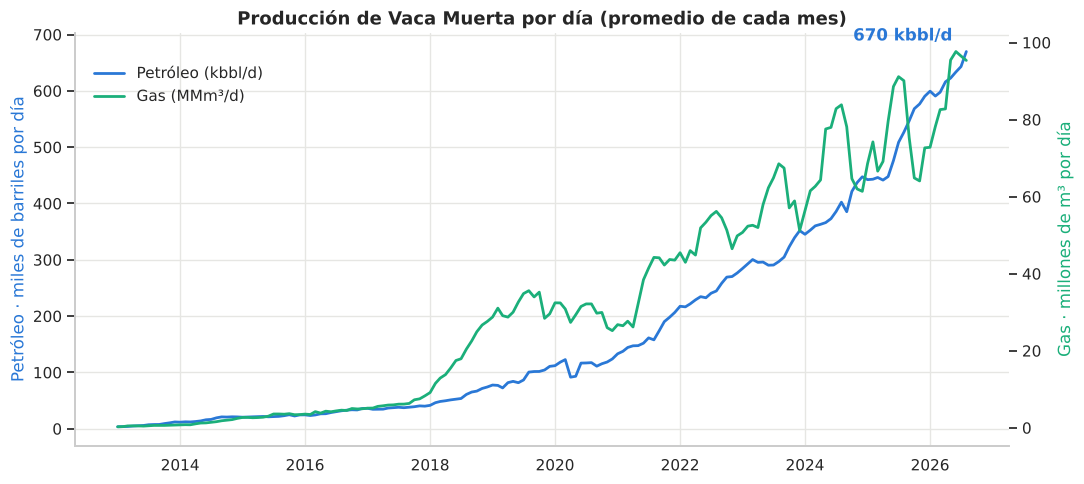

In [7]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(mensual.index, mensual["petroleo_kbbl_d"], color=COLOR["petroleo"], lw=2, label="Petróleo (kbbl/d)")
ax1.set_ylabel("Petróleo · miles de barriles por día", color=COLOR["petroleo"])
ax2 = ax1.twinx()
ax2.plot(mensual.index, mensual["gas_MMm3_d"], color=COLOR["gas"], lw=2, label="Gas (MMm³/d)")
ax2.set_ylabel("Gas · millones de m³ por día", color=COLOR["gas"])
ax2.grid(False)
ultimo = mensual.index[-1]
ax1.annotate(f"{mensual['petroleo_kbbl_d'].iloc[-1]:.0f} kbbl/d", (ultimo, mensual["petroleo_kbbl_d"].iloc[-1]),
             xytext=(-10, 8), textcoords="offset points", ha="right", color=COLOR["petroleo"], fontweight="bold")
ax1.set_title("Producción de Vaca Muerta por día (promedio de cada mes)")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88), frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "01_produccion_mensual.png", dpi=150)
plt.show()

> Usamos dos ejes porque petróleo y gas están en unidades distintas. Ojo al leerlo: la altura de una línea **no** se compara con la de la otra.

## 3. ¿Quién produce?

Tomamos los **últimos 12 meses** disponibles para que el ranking refleje el presente y no la historia.

In [8]:
desde = mensual.index[-12]
ult12 = vm[vm["fecha"] >= desde]
empresas = ult12.groupby("empresa")["prod_pet"].sum().sort_values(ascending=False)
participacion = empresas / empresas.sum() * 100
top = participacion.head(8).copy()
top["Resto"] = participacion.iloc[8:].sum()
print(f"Últimos 12 meses: {desde:%m/%Y} a {mensual.index[-1]:%m/%Y}")
top.round(1).to_frame("% del petróleo de Vaca Muerta")

Últimos 12 meses: 09/2025 a 08/2026


,% del petróleo de Vaca Muerta
empresa,
YPF S.A.,52.5
VISTA ENERGY ARGENTINA SAU,12.7
SHELL ARGENTINA S.A.,5.9
PAN AMERICAN ENERGY SL,5.2
PLUSPETROL CUENCA NEUQUINA S.R.L.,4.5
PLUSPETROL S.A.,4.5
CHEVRON ARGENTINA S.R.L.,3.5
TECPETROL S.A.,3.2
Resto,7.9


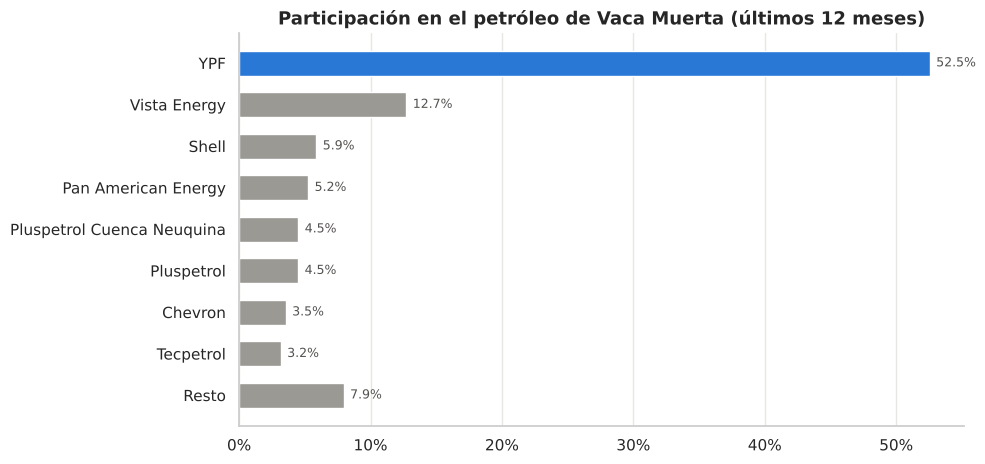

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colores = [COLOR["petroleo"]] + [COLOR["resto"]] * (len(top) - 1)
def nombre_corto(e):
    # Saca la forma legal (S.A., S.R.L., etc.) y deja siglas como YPF en mayúsculas
    for sufijo in [" S.A.U.", " S.A.", " SAU", " S.R.L.", " SL", " ARGENTINA"]:
        e = e.replace(sufijo, "")
    return e if len(e) <= 4 else e.title()
etiquetas = [nombre_corto(e) for e in top.index]
ax.barh(etiquetas, top.values, color=colores, height=0.6)
for i, v in enumerate(top.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9, color=COLOR["texto"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.set_title("Participación en el petróleo de Vaca Muerta (últimos 12 meses)")
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "02_empresas.png", dpi=150)
plt.show()

## 4. ¿Dónde están los pozos?

Cada punto es un pozo, ubicado con sus coordenadas y coloreado según el petróleo que produjo en total (acumulado).
En la app esto va a ser un mapa interactivo; acá alcanza con un gráfico de dispersión para ver la forma.

Pozos con coordenadas válidas: 3,417 de 3,417


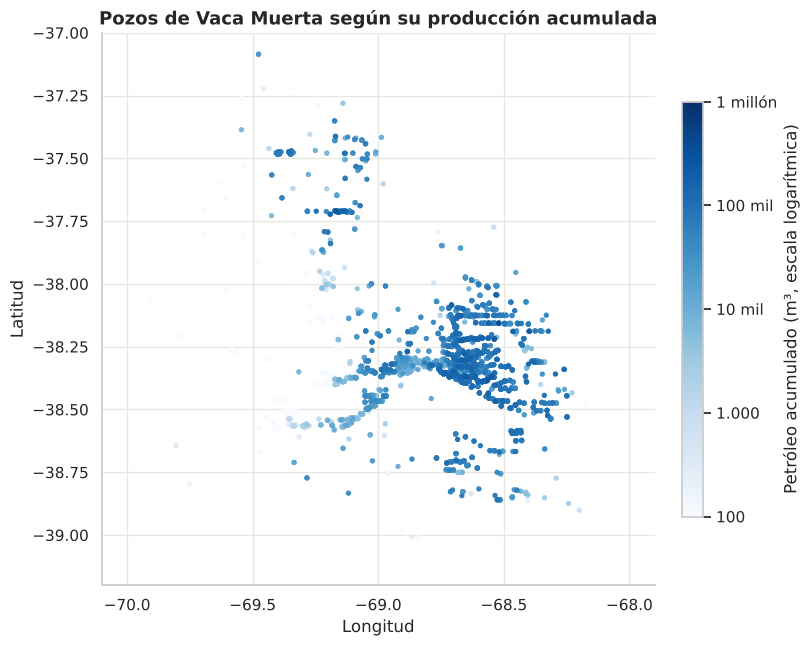

In [10]:
pozos = (vm.groupby("idpozo")
           .agg(x=("coordenadax", "last"), y=("coordenaday", "last"),
                pet_acum=("prod_pet", "sum"), empresa=("empresa", "last"))
           .query("x < -60 and y < -30"))   # descarta coordenadas vacías o mal cargadas
print(f"Pozos con coordenadas válidas: {len(pozos):,} de {vm['idpozo'].nunique():,}")

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
orden = pozos.sort_values("pet_acum")   # los mejores pozos se dibujan arriba
sc = ax.scatter(orden["x"], orden["y"], c=np.log10(orden["pet_acum"] + 1), cmap="Blues", s=8, vmin=2, vmax=6)
cb = plt.colorbar(sc, ax=ax, shrink=0.6)
cb.set_label("Petróleo acumulado (m³, escala logarítmica)")
cb.set_ticks([2, 3, 4, 5, 6]); cb.set_ticklabels(["100", "1.000", "10 mil", "100 mil", "1 millón"])
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_aspect("equal")
ax.set_xlim(-70.1, -67.9); ax.set_ylim(-39.2, -37.0)
ax.set_xticks([-70, -69.5, -69, -68.5, -68])   # zoom al núcleo (quedan afuera unos pocos pozos aislados de Mendoza)
ax.set_title("Pozos de Vaca Muerta según su producción acumulada")
plt.savefig(CARPETA_GRAF / "03_mapa_pozos.png", dpi=150)
plt.show()

## 5. Fracturas: ¿cómo se diseñan los pozos?

Esta base tiene una fila por **fractura**. Un mismo pozo puede aparecer más de una vez (por ejemplo, si se lo vuelve a fracturar),
así que lo revisamos antes de usarla.

In [11]:
frac = pd.read_csv(CRUDOS / "fracturas.csv")
frac["arena_total_tn"] = frac["arena_bombeada_nacional_tn"] + frac["arena_bombeada_importada_tn"]
print(f"{len(frac):,} fracturas · {frac['idpozo'].nunique():,} pozos · fracturas entre {frac['anio_if'].min()} y {frac['anio_if'].max()}")
print("Pozos con más de una fractura:", (frac["idpozo"].value_counts() > 1).sum())

frac_vm = frac[frac["formacion_productiva"].str.strip().str.lower() == "vaca muerta"]
print(f"Vaca Muerta: {len(frac_vm):,} fracturas")
frac_vm[["longitud_rama_horizontal_m", "cantidad_fracturas", "arena_total_tn", "agua_inyectada_m3", "presion_maxima_psi"]].describe().round(0)

4,984 fracturas · 4,740 pozos · fracturas entre 2006 y 2026
Pozos con más de una fractura: 183
Vaca Muerta: 3,095 fracturas


,longitud_rama_horizontal_m,cantidad_fracturas,arena_total_tn,agua_inyectada_m3,presion_maxima_psi
count,3095.0,3095.0,3095.0,3095.0,3095.0
mean,2178.0,36.0,8189.0,52909.0,11745.0
std,1133.0,19.0,4777.0,33608.0,6584.0
min,0.0,1.0,45.0,0.0,0.0
25%,1577.0,22.0,4942.0,30669.0,11160.0
50%,2483.0,37.0,8665.0,54250.0,11591.0
75%,2978.0,49.0,11365.0,74805.0,12067.0
max,5114.0,105.0,91094.0,537185.0,209641.0


In [12]:
# ¿Cuántos valores imposibles hay?
print("Ramas horizontales de 0 m:      ", (frac_vm["longitud_rama_horizontal_m"] == 0).sum())
print("Presiones mayores a 20.000 psi: ", (frac_vm["presion_maxima_psi"] > 20000).sum())
print("Sin arena ni agua:              ", ((frac_vm["arena_total_tn"] == 0) & (frac_vm["agua_inyectada_m3"] == 0)).sum())

Ramas horizontales de 0 m:       458
Presiones mayores a 20.000 psi:  9
Sin arena ni agua:               0


**Valores raros que vamos a tener que tratar en la limpieza (Etapa 2):**
- Ramas horizontales de **0 m**: pozos verticales o datos sin cargar.
- Presiones de cientos de miles de psi: imposibles (los equipos de fractura trabajan hasta ~15.000 psi), son errores de carga.

Por ahora, para los gráficos, solo dejamos afuera las ramas de 0 m.

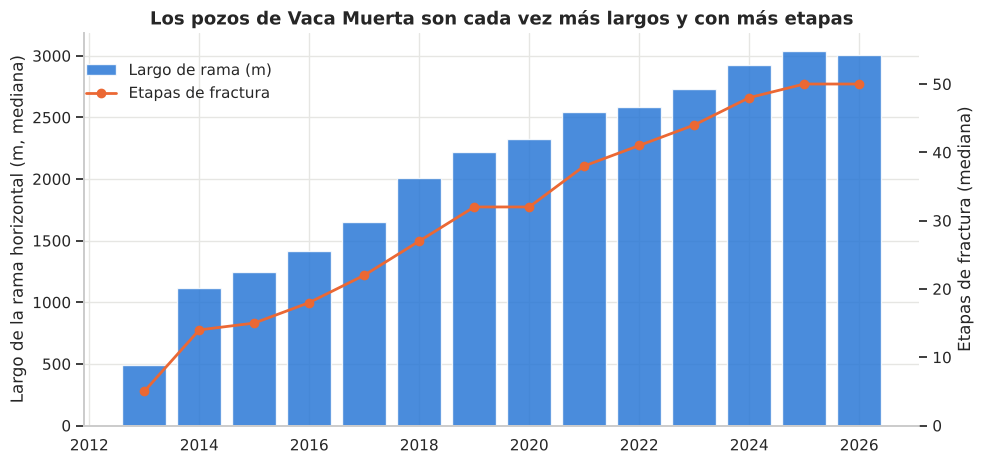

anio_if,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
longitud_rama_horizontal_m,490,1113,1244,1413,1650,2006,2216,2326,2540,2583,2734,2922,3035,3007
cantidad_fracturas,5,14,15,18,22,27,32,32,38,41,44,48,50,50


In [13]:
ok = frac_vm[frac_vm["longitud_rama_horizontal_m"] > 0]
diseño = ok.groupby("anio_if")[["longitud_rama_horizontal_m", "cantidad_fracturas"]].median()
diseño = diseño[diseño.index >= 2013]

fig, ax1 = plt.subplots(figsize=(10, 4.8))
ax1.bar(diseño.index, diseño["longitud_rama_horizontal_m"], color=COLOR["petroleo"], alpha=0.85, label="Largo de rama (m)")
ax1.set_ylabel("Largo de la rama horizontal (m, mediana)")
ax2 = ax1.twinx()
ax2.plot(diseño.index, diseño["cantidad_fracturas"], color=COLOR["acento"], marker="o", lw=2, label="Etapas de fractura")
ax2.set_ylabel("Etapas de fractura (mediana)")
ax2.set_ylim(0, diseño["cantidad_fracturas"].max() * 1.15)
ax2.grid(False)
ax1.set_title("Los pozos de Vaca Muerta son cada vez más largos y con más etapas")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88), frameon=False)
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "04_diseño_pozos.png", dpi=150)
plt.show()
diseño.round(0).astype(int).T

## 6. ¿Se pueden unir producción y fracturas?

Para el modelo de ML necesitamos, por pozo: **cómo se lo fracturó** (base de fracturas) y **cuánto petróleo dio en sus primeros 12 meses** (base de producción).
La columna que las une es `idpozo`. Hacemos una primera prueba:
1. En producción, para cada pozo, sumamos el petróleo de sus **primeros 12 meses con producción**.
2. Solo contamos pozos con al menos 12 meses de historia (si no, el número estaría incompleto).
3. En fracturas nos quedamos con la **primera** fractura de cada pozo.

In [14]:
con_prod = vm[vm["prod_pet"] > 0].sort_values(["idpozo", "fecha"])
con_prod["mes_n"] = con_prod.groupby("idpozo").cumcount() + 1
pet12 = (con_prod[con_prod["mes_n"] <= 12].groupby("idpozo")
         .agg(pet_12m=("prod_pet", "sum"), meses=("mes_n", "max")))
pet12 = pet12[pet12["meses"] == 12]

primera_frac = ok.sort_values("fecha_inicio_fractura").drop_duplicates("idpozo")
tabla = primera_frac.merge(pet12, on="idpozo", how="inner")
print(f"Pozos de VM con 12 meses de producción:  {len(pet12):,}")
print(f"Pozos de VM con fractura válida:         {primera_frac['idpozo'].nunique():,}")
print(f"Pozos que cruzan (tabla para el modelo): {len(tabla):,}")

Pozos de VM con 12 meses de producción:  2,587
Pozos de VM con fractura válida:         2,624
Pozos que cruzan (tabla para el modelo): 1,979


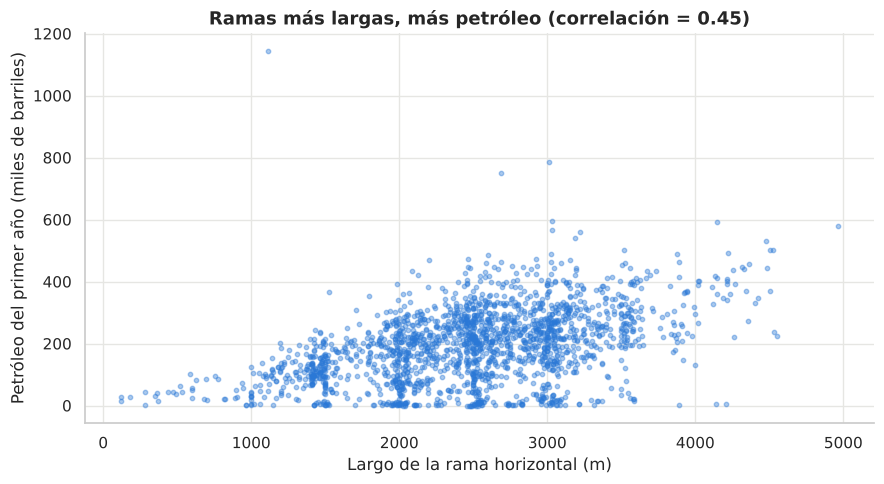

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(tabla["longitud_rama_horizontal_m"], tabla["pet_12m"] * M3_A_BARRILES / 1000,
           s=10, alpha=0.4, color=COLOR["petroleo"])
corr = tabla["longitud_rama_horizontal_m"].corr(tabla["pet_12m"])
ax.set_xlabel("Largo de la rama horizontal (m)")
ax.set_ylabel("Petróleo del primer año (miles de barriles)")
ax.set_title(f"Ramas más largas, más petróleo (correlación = {corr:.2f})")
plt.tight_layout()
plt.savefig(CARPETA_GRAF / "05_rama_vs_produccion.png", dpi=150)
plt.show()

## 7. Conclusiones de la exploración

**Sobre los datos**
- La base de producción va de 2006 a **agosto de 2026** y no tiene duplicados (un registro por pozo y mes). Casi no hay nulos en las columnas importantes.
- **Vaca Muerta es el 96,5% del petróleo** de toda la base no convencional: 3.417 pozos.
- La base de fracturas tiene **458 pozos de Vaca Muerta con rama de 0 m** y **9 presiones imposibles**. Hay que limpiarlos antes del modelo.
- Algunas empresas aparecen con más de un nombre legal (por ejemplo **Pluspetrol S.A.** y **Pluspetrol Cuenca Neuquina S.R.L.**). En la limpieza conviene unificarlas.

**Sobre Vaca Muerta**
- El petróleo pasó de **90 mil barriles por día** (promedio 2019) a **501 mil** (promedio 2025) y **670 mil en agosto de 2026**. Se multiplicó por más de 7.
- Esto conecta con la Parte 2: es el petróleo que explica el giro exportador del Balance Energético.
- Los pozos activos pasaron de ~910 a ~2.730, así que el crecimiento viene de **más pozos** y también de **pozos más productivos**.
- **YPF produce más de la mitad** del petróleo (52,5% en los últimos 12 meses), seguida por Vista (12,7%).
- Los pozos son cada vez más grandes: la rama horizontal pasó de **~500 m (2013) a ~3.000 m (2025)** y las etapas de fractura de 5 a 50.

**Para el modelo de ML (Etapa 5)**
- Al unir las dos bases quedan **1.979 pozos** con fractura y 12 meses de producción: alcanza para entrenar un modelo.
- El largo de la rama ya muestra una relación clara con el petróleo del primer año (**correlación 0,45**).
- Los puntos cerca de 0 en el último gráfico son, sobre todo, **pozos de gas**. Para predecir petróleo habrá que separarlos.

**Próximo paso (Etapa 2):** un script `procesar.py` que haga esta limpieza y guarde archivos Parquet livianos para que la app cargue rápido.